# Heart disease (UCI Cleveland): exploratory data analysis

303 patients referred for angiography at the Cleveland Clinic; 13 attributes; outcome = angiographic disease (> 50% narrowing in any major vessel).

> Part of the MediAssist CDSS project. Data loading and cleaning live in `ml/src/medml/data.py`, so this notebook and the training pipeline see exactly the same data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from medml.data import load

sns.set_theme(style="whitegrid", palette="crest")
pd.set_option("display.precision", 2)

In [2]:
data = load("heart")
df = data.X.assign(target=data.y)
print(data.source)
print(df.shape)
df.head()

UCI Heart Disease, Cleveland subset (Janosi et al., 1988)
(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cleaning applied

In [3]:
for step in data.cleaning_log:
    print("-", step)

- Missing values ('?') found: {'ca': 4, 'thal': 2}; imputed inside the pipeline
- Target 'num' (0-4 severity) binarised: 0 = no disease, 1-4 = disease present
- Categorical codes (cp, restecg, slope, thal) one-hot encoded so they are not treated as ordered numbers
- Original 303-row UCI Cleveland file used instead of the 1,025-row Kaggle copy, which contains repeated patients and leaks between train and test


## Summary statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## Class balance and missing values

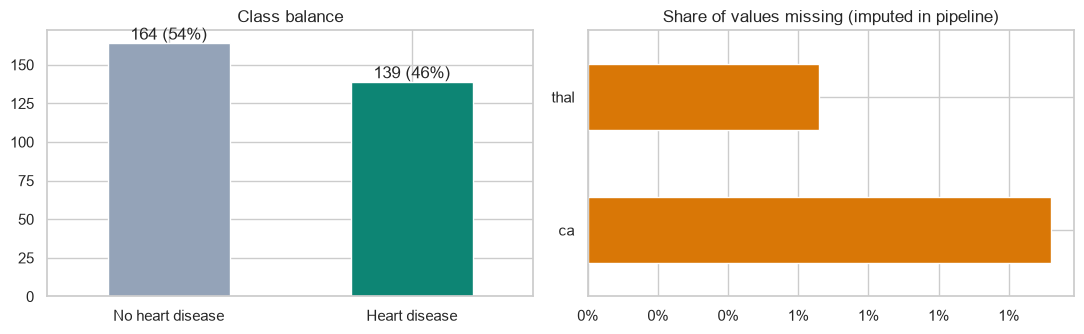

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
balance = pd.Series(data.class_balance())
balance.plot.bar(ax=axes[0], color=["#94a3b8", "#0d8574"], rot=0)
axes[0].set_title("Class balance")
for i, v in enumerate(balance):
    axes[0].text(i, v, f"{v} ({v / balance.sum():.0%})", ha="center", va="bottom")
missing = data.X.isna().mean().sort_values(ascending=False)
missing[missing > 0].plot.barh(ax=axes[1], color="#d97706")
axes[1].set_title("Share of values missing (imputed in pipeline)")
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout()

## Feature distributions by outcome

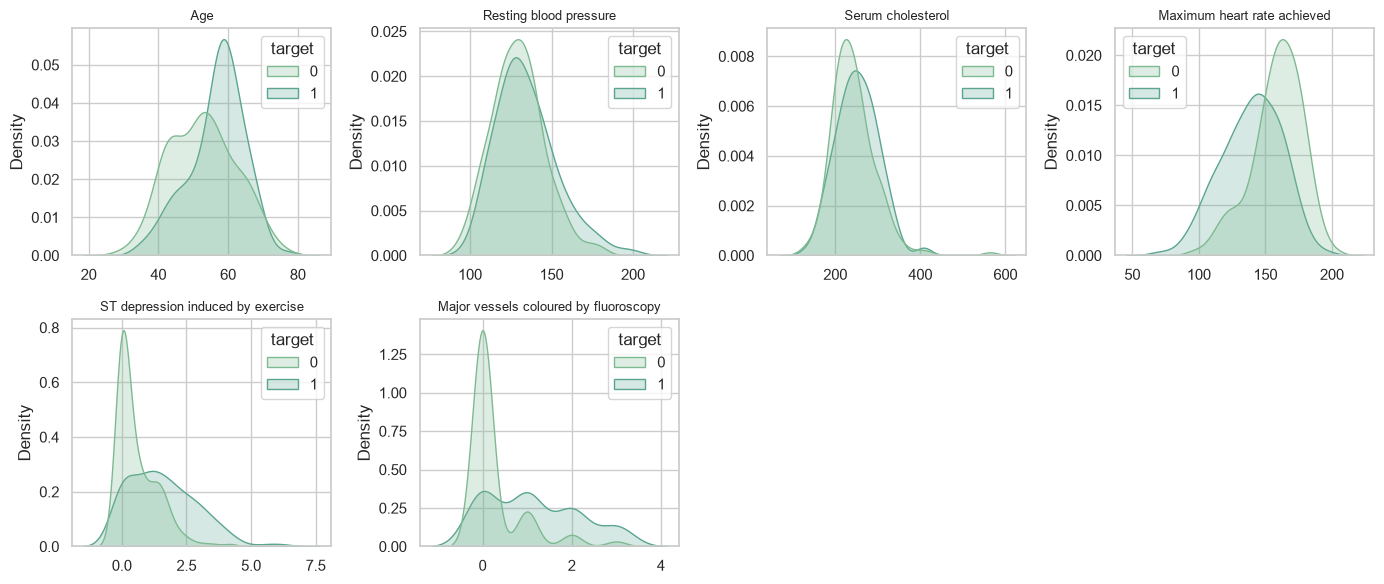

In [6]:
numeric = [f.name for f in data.features if f.kind == "numeric"]
labels = {f.name: f.label for f in data.features}
cols = 4
rows = int(np.ceil(len(numeric) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3 * rows))
for ax, col in zip(axes.flat, numeric):
    sns.kdeplot(
        data=df, x=col, hue="target", common_norm=False, fill=True, ax=ax, warn_singular=False
    )
    ax.set_title(labels[col], fontsize=9)
    ax.set_xlabel("")
for ax in list(axes.flat)[len(numeric) :]:
    ax.remove()
plt.tight_layout()

## Correlation with the outcome

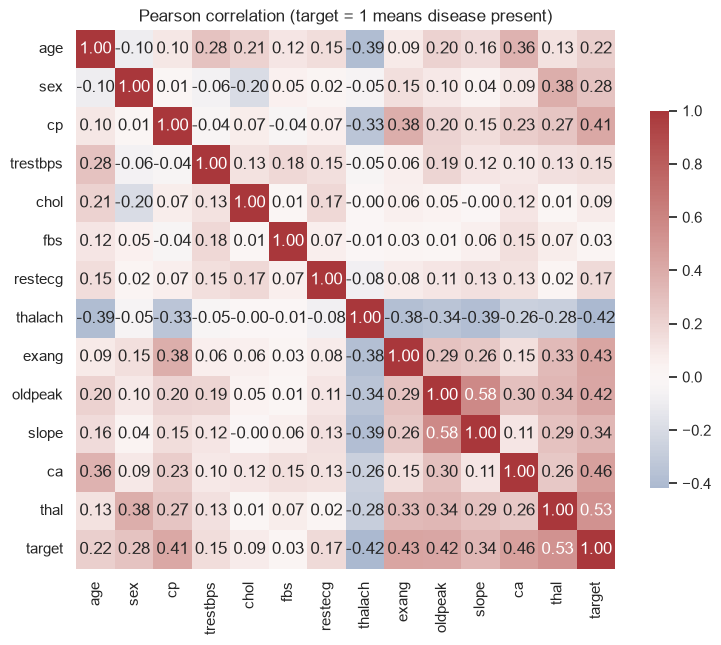

thal        0.53
ca          0.46
exang       0.43
oldpeak     0.42
thalach    -0.42
cp          0.41
slope       0.34
sex         0.28
age         0.22
restecg     0.17
trestbps    0.15
chol        0.09
fbs         0.03
Name: target, dtype: float64

In [7]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.7}
)
plt.title("Pearson correlation (target = 1 means disease present)")
plt.show()
corr["target"].drop("target").sort_values(key=abs, ascending=False)

## Disease rate by categorical feature

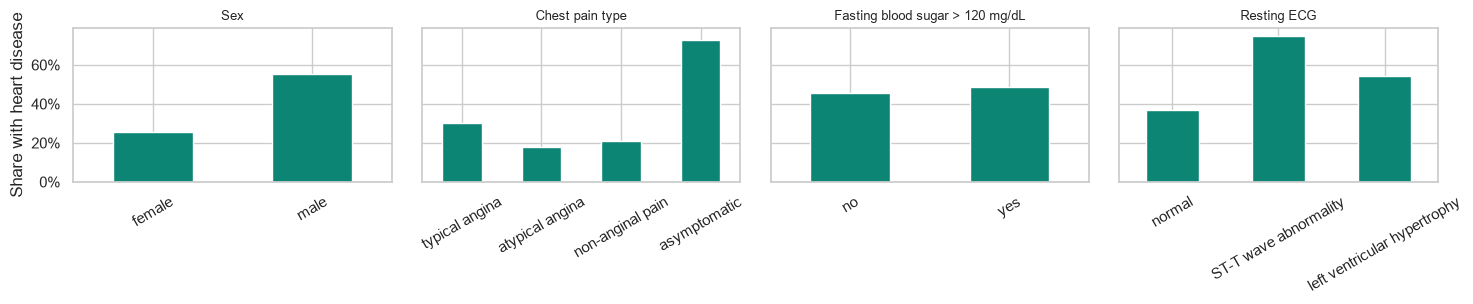

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, f in zip(axes, [s for s in data.features if s.kind != "numeric"][:4]):
    rate = df.groupby(f.name)["target"].mean()
    rate.index = [f.choices.get(str(int(i)), i) for i in rate.index]
    rate.plot.bar(ax=ax, color="#0d8574", rot=30)
    ax.set_title(f.label, fontsize=9)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_ylabel("Share with heart disease")
plt.tight_layout()

## Observations

- **Nearly balanced** (164 vs 139), so accuracy is meaningful here, but F1 is still used for consistency.
- **Strongest signals:** thallium test result (`thal`), number of vessels on fluoroscopy (`ca`), asymptomatic chest pain (`cp = 4`), exercise-induced angina and ST depression (`oldpeak`). Max heart rate is *negatively* associated with disease.
- Counter-intuitively, *asymptomatic* chest pain has the highest disease rate. This is a known property of this referral population and is worth explaining in the viva.
- Categorical codes are one-hot encoded so the tree never assumes e.g. `thal 7 > thal 6`.